# scTranslator 10K Benchmark on Three Validation Datasets

Benchmarks the **10K** checkpoint on three validation datasets: **iTRAQ**, **LabelFree**, **TMT**.

Threshold-based NaN handling: columns with >50% NaN are dropped; remaining NaN values are filled with `1e-8` (0 is reserved by the decoder)

## 1. Imports

In [1]:
import os
import sys
import pickle
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## 2. Paths & Configuration

In [2]:
SCTRANSLATOR_REPO = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator'
CHECKPOINT_DIR    = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff'

SCRIPT_DIR = os.path.dirname(os.path.abspath('__file__'))

sys.path.append(os.path.join(SCTRANSLATOR_REPO, 'code', 'model'))
from performer_enc_dec import scPerformerEncDec

CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'scTranslator_10K.pt')

DATASETS = {
    'iTRAQ': {
        'rna_path':  os.path.join(SCRIPT_DIR, 'iTRAQ_transcriptomics.joblib'),
        'prot_path': os.path.join(SCRIPT_DIR, 'iTRAQ_proteomics.joblib'),
    },
    'LabelFree': {
        'rna_path':  os.path.join(SCRIPT_DIR, 'LabelFree_transcriptomics.joblib'),
        'prot_path': os.path.join(SCRIPT_DIR, 'LabelFree_proteomics.joblib'),
    },
    'TMT': {
        'rna_path':  os.path.join(SCRIPT_DIR, 'TMT_transcriptomics.joblib'),
        'prot_path': os.path.join(SCRIPT_DIR, 'TMT_proteomics.joblib'),
    },
}

COMMON_CONFIG = {
    'dic_path':        os.path.join(SCTRANSLATOR_REPO, 'code', 'model', 'ID_dic'),
    'enc_max_seq_len': 20000,
    'dec_max_seq_len': 1000,
    'batch_size':      8,
    'output_dir':      os.path.join(SCRIPT_DIR, 'benchmark_results_10K_allval'),
}

print(f"SCRIPT_DIR:        {SCRIPT_DIR}")
print(f"SCTRANSLATOR_REPO: {SCTRANSLATOR_REPO}")
print(f"CHECKPOINT_DIR:    {CHECKPOINT_DIR}")
print(f"CHECKPOINT_PATH:   {CHECKPOINT_PATH}")

status = 'FOUND' if os.path.exists(CHECKPOINT_PATH) else 'MISSING'
print(f"  [{status}] 10K: {CHECKPOINT_PATH}")

print("\nDatasets:")
for ds_name, ds_paths in DATASETS.items():
    rna_ok  = 'FOUND' if os.path.exists(ds_paths['rna_path'])  else 'MISSING'
    prot_ok = 'FOUND' if os.path.exists(ds_paths['prot_path']) else 'MISSING'
    print(f"  {ds_name}: RNA [{rna_ok}], Protein [{prot_ok}]")

SCRIPT_DIR:        c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val
SCTRANSLATOR_REPO: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator
CHECKPOINT_DIR:    C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff
CHECKPOINT_PATH:   C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt
  [FOUND] 10K: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt

Datasets:
  iTRAQ: RNA [FOUND], Protein [FOUND]
  LabelFree: RNA [FOUND], Protein [FOUND]
  TMT: RNA [FOUND], Protein [FOUND]


## 3. ID Mapping Helpers

In [3]:
def load_id_dictionaries(dic_path):
    """Load scTranslator ID mapping dictionaries."""
    with open(os.path.join(dic_path, 'hgs_to_EntrezID.pkl'), 'rb') as f:
        hgs_to_entrez = pickle.load(f)
    with open(os.path.join(dic_path, 'EntrezID_to_myID.pkl'), 'rb') as f:
        entrez_to_myid = pickle.load(f)
    return hgs_to_entrez, entrez_to_myid


def gene_symbol_to_myid(gene_symbol, hgs_to_entrez, entrez_to_myid):
    """Convert gene symbol to scTranslator ID."""
    entrez_id = hgs_to_entrez.get(gene_symbol)
    if entrez_id:
        my_id = entrez_to_myid.get(entrez_id)
        return int(my_id) if my_id else None
    return None


def map_genes_to_ids(gene_list, hgs_to_entrez, entrez_to_myid):
    """Map a list of gene symbols to scTranslator IDs."""
    mapped = []
    unmapped = []
    for gene in gene_list:
        my_id = gene_symbol_to_myid(gene, hgs_to_entrez, entrez_to_myid)
        if my_id is not None:
            mapped.append((gene, my_id))
        else:
            unmapped.append(gene)
    return mapped, unmapped

## 4. Normalization

In [4]:
def cellwise_minmax(X, low=1e-8, high=1.0):
    """
    Paper's normalization: per-cell min-max scaling.
    Maps each cell's values to [low, high] range.
    """
    X = X.astype(np.float32)
    mins = X.min(axis=1, keepdims=True)
    maxs = X.max(axis=1, keepdims=True)
    denom = (maxs - mins)
    denom[denom == 0] = 1.0
    Xn = (X - mins) / denom
    Xn = Xn * (high - low) + low
    return Xn.astype(np.float32)

## 5. Data Preparation (NaN Handling + ID Mapping)

**NaN strategy (threshold-based):**
- Columns where **>50 %** of values across samples are NaN are **dropped**.
- Remaining NaN values are **filled with `1e-8`** (a small non-zero value; 0 is the special prediction token for scTranslator's decoder).

In [17]:
def prepare_data(config):
    """
    Load and prepare RNA and protein data with ID mapping.

    If config contains 'overlap_genes_path' and/or 'overlap_proteins_path',
    the RNA/protein columns are restricted to those overlap lists before
    NaN handling and ID mapping.
    """
    NAN_THRESHOLD = 0.50

    print("Loading data...")
    rna_df = joblib.load(config['rna_path'])
    prot_df = joblib.load(config['prot_path'])

    print(f"RNA shape (raw):     {rna_df.shape}")
    print(f"Protein shape (raw): {prot_df.shape}")

    # ── Optional overlap filtering ──────────────────────────────────────
    overlap_mode = False
    if config.get('overlap_genes_path') and os.path.exists(config['overlap_genes_path']):
        overlap_genes = pd.read_csv(config['overlap_genes_path'], header=None)[0].tolist()
        rna_keep = [g for g in rna_df.columns if g in set(overlap_genes)]
        rna_df = rna_df[rna_keep]
        overlap_mode = True
        print(f"[OVERLAP] Restricted RNA genes to overlap list: {len(overlap_genes)} allowed -> {len(rna_keep)} kept")
    if config.get('overlap_proteins_path') and os.path.exists(config['overlap_proteins_path']):
        overlap_proteins = pd.read_csv(config['overlap_proteins_path'], header=None)[0].tolist()
        prot_keep = [p for p in prot_df.columns if p in set(overlap_proteins)]
        prot_df = prot_df[prot_keep]
        overlap_mode = True
        print(f"[OVERLAP] Restricted proteins to overlap list:  {len(overlap_proteins)} allowed -> {len(prot_keep)} kept")

    if overlap_mode:
        print(f"[OVERLAP] RNA shape (after overlap filter):     {rna_df.shape}")
        print(f"[OVERLAP] Protein shape (after overlap filter): {prot_df.shape}")
    else:
        print("(No overlap filtering applied -- using all genes/proteins)")

    rna_orig_cols  = len(rna_df.columns)
    prot_orig_cols = len(prot_df.columns)
    n_samples_rna  = len(rna_df)
    n_samples_prot = len(prot_df)

    rna_nan_frac  = rna_df.isna().sum() / n_samples_rna
    prot_nan_frac = prot_df.isna().sum() / n_samples_prot

    rna_drop_cols  = rna_nan_frac[rna_nan_frac > NAN_THRESHOLD].index.tolist()
    prot_drop_cols = prot_nan_frac[prot_nan_frac > NAN_THRESHOLD].index.tolist()

    rna_fill_cols  = rna_nan_frac[(rna_nan_frac > 0) & (rna_nan_frac <= NAN_THRESHOLD)].index.tolist()
    prot_fill_cols = prot_nan_frac[(prot_nan_frac > 0) & (prot_nan_frac <= NAN_THRESHOLD)].index.tolist()

    rna_df  = rna_df.drop(columns=rna_drop_cols)
    prot_df = prot_df.drop(columns=prot_drop_cols)

    rna_df  = rna_df.fillna(1e-8)
    prot_df = prot_df.fillna(1e-8)

    print(f"\nNaN handling (threshold: >{NAN_THRESHOLD*100:.0f}% NaN -> drop, else fill with 1e-8):")
    print(f"  RNA genes dropped  (>{NAN_THRESHOLD*100:.0f}% NaN): {len(rna_drop_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_drop_cols)/rna_orig_cols:.1f}%)")
    print(f"  RNA genes filled   (<=50% NaN):  {len(rna_fill_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_fill_cols)/rna_orig_cols:.1f}%)")
    print(f"  Proteins dropped   (>{NAN_THRESHOLD*100:.0f}% NaN): {len(prot_drop_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_drop_cols)/prot_orig_cols:.1f}%)")
    print(f"  Proteins filled    (<=50% NaN):  {len(prot_fill_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_fill_cols)/prot_orig_cols:.1f}%)")
    print(f"  RNA shape after:     {rna_df.shape}")
    print(f"  Protein shape after: {prot_df.shape}")

    hgs_to_entrez, entrez_to_myid = load_id_dictionaries(config['dic_path'])

    print("\nMapping RNA genes to scTranslator IDs...")
    rna_mapped, rna_unmapped = map_genes_to_ids(
        rna_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  RNA genes after NaN removal: {len(rna_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(rna_mapped)} ({100*len(rna_mapped)/len(rna_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(rna_unmapped)} ({100*len(rna_unmapped)/len(rna_df.columns):.1f}%)")
    if rna_unmapped:
        print(f"  First 20 unmapped genes:     {rna_unmapped[:20]}")

    print("\nMapping proteins to scTranslator IDs...")
    prot_mapped, prot_unmapped = map_genes_to_ids(
        prot_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  Proteins after NaN removal:  {len(prot_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(prot_mapped)} ({100*len(prot_mapped)/len(prot_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(prot_unmapped)} ({100*len(prot_unmapped)/len(prot_df.columns):.1f}%)")
    if prot_unmapped:
        print(f"  Unmapped proteins:           {prot_unmapped}")

    print(f"\n  === Total gene / protein attrition ===")
    print(f"  RNA:  {rna_orig_cols} -> {len(rna_mapped)}  "
          f"(dropped {len(rna_drop_cols)} NaN + {len(rna_unmapped)} unmapped "
          f"= {rna_orig_cols - len(rna_mapped)} total removed, "
          f"{len(rna_fill_cols)} cols NaN-filled)")
    print(f"  Prot: {prot_orig_cols} -> {len(prot_mapped)}  "
          f"(dropped {len(prot_drop_cols)} NaN + {len(prot_unmapped)} unmapped "
          f"= {prot_orig_cols - len(prot_mapped)} total removed, "
          f"{len(prot_fill_cols)} cols NaN-filled)")

    rna_genes  = [g for g, _ in rna_mapped]
    rna_ids    = [i for _, i in rna_mapped]
    prot_genes = [g for g, _ in prot_mapped]
    prot_ids   = [i for _, i in prot_mapped]

    rna_values  = rna_df[rna_genes].values
    prot_values = prot_df[prot_genes].values

    print("\nApplying cell-wise min-max normalization...")
    rna_norm  = cellwise_minmax(rna_values)
    prot_norm = cellwise_minmax(prot_values)

    return {
        'rna_values':  rna_norm,
        'rna_ids':     np.array(rna_ids),
        'rna_genes':   rna_genes,
        'prot_values': prot_norm,
        'prot_ids':    np.array(prot_ids),
        'prot_genes':  prot_genes,
        'cell_names':  rna_df.index.tolist(),
        'n_cells':     rna_df.shape[0],
        'n_rna_genes': len(rna_genes),
        'n_proteins':  len(prot_genes),
        'mapping_stats': {
            'rna_total':           rna_orig_cols,
            'rna_dropped_nan':     len(rna_drop_cols),
            'rna_filled_nan':      len(rna_fill_cols),
            'rna_after_nan':       len(rna_df.columns),
            'rna_mapped':          len(rna_mapped),
            'rna_unmapped':        len(rna_unmapped),
            'prot_total':          prot_orig_cols,
            'prot_dropped_nan':    len(prot_drop_cols),
            'prot_filled_nan':     len(prot_fill_cols),
            'prot_after_nan':      len(prot_df.columns),
            'prot_mapped':         len(prot_mapped),
            'prot_unmapped':       len(prot_unmapped),
            'prot_unmapped_names': prot_unmapped,
            'nan_threshold':       NAN_THRESHOLD,
        },
    }

## 6. Model Inference

In [6]:
def prepare_batch(rna_values, rna_ids, prot_ids, enc_max_len, dec_max_len, device):
    """Prepare a batch for model inference."""
    batch_size = rna_values.shape[0]
    n_rna  = rna_values.shape[1]
    n_prot = len(prot_ids)

    if n_rna >= enc_max_len:
        rna_val  = rna_values[:, :enc_max_len]
        rna_id   = np.tile(rna_ids[:enc_max_len], (batch_size, 1))
        rna_mask = np.ones((batch_size, enc_max_len), dtype=bool)
    else:
        rna_val = np.zeros((batch_size, enc_max_len), dtype=np.float32)
        rna_val[:, :n_rna] = rna_values
        rna_id = np.zeros((batch_size, enc_max_len), dtype=np.int64)
        rna_id[:, :n_rna] = rna_ids
        rna_mask = np.zeros((batch_size, enc_max_len), dtype=bool)
        rna_mask[:, :n_rna] = True

    prot_val  = np.zeros((batch_size, dec_max_len), dtype=np.float32)
    prot_id   = np.zeros((batch_size, dec_max_len), dtype=np.int64)
    prot_mask = np.zeros((batch_size, dec_max_len), dtype=bool)

    prot_id[:, :n_prot]   = prot_ids
    prot_mask[:, :n_prot] = True

    rna_val_t   = torch.tensor(rna_val,  dtype=torch.float32).to(device)
    rna_id_t    = torch.tensor(rna_id,   dtype=torch.long).to(device)
    rna_mask_t  = torch.tensor(rna_mask,  dtype=torch.bool).to(device)
    prot_id_t   = torch.tensor(prot_id,  dtype=torch.long).to(device)
    prot_mask_t = torch.tensor(prot_mask, dtype=torch.bool).to(device)

    return rna_val_t, rna_id_t, rna_mask_t, prot_id_t, prot_mask_t, n_prot


def run_inference(model, data, config, device):
    """Run inference on all cells, chunking proteins as needed."""
    model.eval()

    n_cells    = data['n_cells']
    n_proteins = data['n_proteins']
    dec_max    = config['dec_max_seq_len']
    batch_size = config['batch_size']

    n_chunks = int(np.ceil(n_proteins / dec_max))
    print(f"\nProtein chunking: {n_proteins} proteins -> {n_chunks} chunks of <={dec_max}")

    all_predictions = np.zeros((n_cells, n_proteins), dtype=np.float32)

    for chunk_idx in range(n_chunks):
        start_prot = chunk_idx * dec_max
        end_prot   = min((chunk_idx + 1) * dec_max, n_proteins)
        chunk_prot_ids = data['prot_ids'][start_prot:end_prot]
        chunk_size = end_prot - start_prot

        print(f"  Chunk {chunk_idx+1}/{n_chunks}: proteins {start_prot}-{end_prot} ({chunk_size} proteins)")

        chunk_predictions = []

        for batch_start in tqdm(range(0, n_cells, batch_size), desc=f"  Chunk {chunk_idx+1}"):
            batch_end = min(batch_start + batch_size, n_cells)
            batch_rna = data['rna_values'][batch_start:batch_end]

            rna_val, rna_id, rna_mask, prot_id, prot_mask, n_prot = prepare_batch(
                batch_rna, data['rna_ids'], chunk_prot_ids,
                config['enc_max_seq_len'], dec_max, device
            )

            with torch.no_grad():
                _, y_hat = model(rna_val, rna_id, prot_id,
                                 enc_mask=rna_mask, dec_mask=prot_mask)
                y_hat = torch.squeeze(y_hat)

                if len(y_hat.shape) == 1:
                    y_hat = y_hat.unsqueeze(0)

                y_hat_valid = y_hat[:, :chunk_size].cpu().numpy()
                chunk_predictions.append(y_hat_valid)

        chunk_predictions = np.vstack(chunk_predictions)
        all_predictions[:, start_prot:end_prot] = chunk_predictions

    return all_predictions

## 7. Metrics

In [7]:
def compute_metrics(y_true, y_pred):
    """
    Per-cell (sample-wise) metrics, then averaged:
    cosine similarity, PCC, MSE, MAE.
    """
    n_cells = y_true.shape[0]

    cosines, pccs, mses, maes = [], [], [], []

    for i in range(n_cells):
        true_i = y_true[i]
        pred_i = y_pred[i]

        norm_true = np.linalg.norm(true_i)
        norm_pred = np.linalg.norm(pred_i)
        cos = np.dot(true_i, pred_i) / (norm_true * norm_pred) if (norm_true > 0 and norm_pred > 0) else 0.0
        cosines.append(cos)

        pcc = pearsonr(true_i, pred_i)[0] if (np.std(true_i) > 0 and np.std(pred_i) > 0) else 0.0
        pccs.append(pcc)

        mses.append(mean_squared_error(true_i, pred_i))
        maes.append(mean_absolute_error(true_i, pred_i))

    return {
        'cosine': np.array(cosines),
        'pcc':    np.array(pccs),
        'mse':    np.array(mses),
        'mae':    np.array(maes),
    }


def compute_protein_wise_metrics(y_true, y_pred):
    """Compute PCC and Cosine per protein (across all cells)."""
    n_proteins = y_true.shape[1]
    pccs = []
    cosines = []
    for j in range(n_proteins):
        true_j = y_true[:, j]
        pred_j = y_pred[:, j]

        pcc = pearsonr(true_j, pred_j)[0] if (np.std(true_j) > 0 and np.std(pred_j) > 0) else 0.0
        pccs.append(pcc)

        norm_true = np.linalg.norm(true_j)
        norm_pred = np.linalg.norm(pred_j)
        cos = np.dot(true_j, pred_j) / (norm_true * norm_pred) if (norm_true > 0 and norm_pred > 0) else 0.0
        cosines.append(cos)

    return {'PCC': np.array(pccs), 'Cosine': np.array(cosines)}

## 8. Visualization

In [8]:
def plot_results(metrics, protein_metrics, prot_genes, dataset_name, output_dir):
    """Generate visualization plots."""
    os.makedirs(output_dir, exist_ok=True)

    protein_pccs = protein_metrics['PCC']

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'scTranslator 10K Benchmark \u2013 {dataset_name}', fontsize=14)

    ax = axes[0, 0]
    ax.hist(metrics['cosine'], bins=30, edgecolor='black', alpha=0.7)
    ax.axvline(metrics['cosine'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["cosine"].mean():.3f}')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell Cosine Similarity')
    ax.legend()

    ax = axes[0, 1]
    ax.hist(metrics['pcc'], bins=30, edgecolor='black', alpha=0.7, color='orange')
    ax.axvline(metrics['pcc'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["pcc"].mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell PCC')
    ax.legend()

    ax = axes[0, 2]
    ax.hist(metrics['mse'], bins=30, edgecolor='black', alpha=0.7, color='green')
    ax.axvline(metrics['mse'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["mse"].mean():.4f}')
    ax.set_xlabel('MSE')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell MSE')
    ax.legend()

    ax = axes[1, 0]
    ax.hist(protein_pccs, bins=50, edgecolor='black', alpha=0.7, color='purple')
    ax.axvline(protein_pccs.mean(), color='red', linestyle='--',
               label=f'Mean: {protein_pccs.mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Protein PCC (across cells)')
    ax.legend()

    ax = axes[1, 1]
    sorted_idx = np.argsort(protein_pccs)[::-1]
    top_10    = sorted_idx[:10]
    bottom_10 = sorted_idx[-10:]

    proteins_to_show = list(top_10) + list(bottom_10)
    labels = [prot_genes[i] for i in proteins_to_show]
    values = [protein_pccs[i] for i in proteins_to_show]
    colors = ['green'] * 10 + ['red'] * 10

    ax.barh(range(20), values, color=colors, alpha=0.7)
    ax.set_yticks(range(20))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('PCC')
    ax.set_title('Top 10 / Bottom 10 Proteins by PCC')
    ax.axvline(0, color='black', linestyle='-', linewidth=0.5)

    ax = axes[1, 2]
    ax.axis('off')
    summary_text = f"""
    Summary Statistics ({dataset_name} - 10K)
    =====================================

    Per-Cell Metrics (n={len(metrics['cosine'])} cells):

    Cosine Similarity:
      Mean: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}
      Min:  {metrics['cosine'].min():.4f}
      Max:  {metrics['cosine'].max():.4f}

    Pearson Correlation:
      Mean: {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}
      Min:  {metrics['pcc'].min():.4f}
      Max:  {metrics['pcc'].max():.4f}

    MSE:
      Mean: {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}

    MAE:
      Mean: {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}

    Per-Protein PCC (n={len(protein_pccs)} proteins):
      Mean: {protein_pccs.mean():.4f} +/- {protein_pccs.std():.4f}
      Positive: {(protein_pccs > 0).sum()} ({100*(protein_pccs > 0).mean():.1f}%)
      > 0.3:    {(protein_pccs > 0.3).sum()} ({100*(protein_pccs > 0.3).mean():.1f}%)
      > 0.5:    {(protein_pccs > 0.5).sum()} ({100*(protein_pccs > 0.5).mean():.1f}%)
    """
    ax.text(0.1, 0.9, summary_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', fontfamily='monospace')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'benchmark_{dataset_name}_10K.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: benchmark_{dataset_name}_10K.png")


def plot_scatter_examples(y_true, y_pred, prot_genes, protein_metrics, dataset_name, output_dir):
    """Plot scatter plots for selected proteins."""
    protein_pccs = protein_metrics['PCC']
    sorted_idx   = np.argsort(protein_pccs)[::-1]

    n = len(sorted_idx)
    indices = [
        sorted_idx[0],
        sorted_idx[n // 4],
        sorted_idx[n // 2],
        sorted_idx[3*n // 4],
        sorted_idx[-1],
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    fig.suptitle(f'True vs Predicted Protein Abundance \u2013 {dataset_name} (10K)', fontsize=12)

    for ax, idx in zip(axes, indices):
        true_vals = y_true[:, idx]
        pred_vals = y_pred[:, idx]
        pcc = protein_pccs[idx]

        ax.scatter(true_vals, pred_vals, alpha=0.5, s=10)
        ax.plot([true_vals.min(), true_vals.max()],
                [true_vals.min(), true_vals.max()],
                'r--', linewidth=1)
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{prot_genes[idx]}\nPCC={pcc:.3f}')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'scatter_{dataset_name}_10K.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: scatter_{dataset_name}_10K.png")

## 9. Benchmark Runner (single dataset)

In [9]:
def benchmark_dataset(dataset_name, model, data, config, device):
    """Run benchmark for a single dataset using the 10K model."""
    print(f"\n{'='*60}")
    print(f"Benchmarking dataset: {dataset_name} (10K checkpoint)")
    print(f"{'='*60}")

    print("\nRunning inference...")
    predictions = run_inference(model, data, config, device)

    expected_cells    = data['n_cells']
    expected_proteins = data['n_proteins']
    if predictions.shape != (expected_cells, expected_proteins):
        raise ValueError(
            f"Shape mismatch: got {predictions.shape}, "
            f"expected ({expected_cells}, {expected_proteins})"
        )

    ds_output_dir = os.path.join(config['output_dir'], dataset_name)
    os.makedirs(ds_output_dir, exist_ok=True)

    pred_path = os.path.join(ds_output_dir, f'predictions_10K.npy')
    np.save(pred_path, predictions)
    np.save(os.path.join(ds_output_dir, f'protein_names_10K.npy'),
            np.array(data['prot_genes']))
    np.save(os.path.join(ds_output_dir, f'protein_ids_10K.npy'),
            np.array(data['prot_ids']))
    np.save(os.path.join(ds_output_dir, f'cell_names_10K.npy'),
            np.array(data['cell_names']))
    np.savez(
        os.path.join(ds_output_dir, f'predictions_10K.npz'),
        predictions=predictions,
        protein_names=np.array(data['prot_genes']),
        protein_ids=np.array(data['prot_ids']),
        cell_names=np.array(data['cell_names']),
    )
    print(f"  Saved predictions: {pred_path}")

    print("\nComputing metrics...")
    metrics         = compute_metrics(data['prot_values'], predictions)
    protein_metrics = compute_protein_wise_metrics(data['prot_values'], predictions)

    print(f"\n--- Results for {dataset_name} (10K) ---")
    print(f"Per-Cell Cosine: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}")
    print(f"Per-Cell PCC:    {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}")
    print(f"Per-Cell MSE:    {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}")
    print(f"Per-Cell MAE:    {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}")
    print(f"Per-Protein PCC: {protein_metrics['PCC'].mean():.4f} +/- {protein_metrics['PCC'].std():.4f}")
    print(f"Per-Protein Cos: {protein_metrics['Cosine'].mean():.4f} +/- {protein_metrics['Cosine'].std():.4f}")

    print("\nGenerating visualizations...")
    plot_results(metrics, protein_metrics, data['prot_genes'],
                 dataset_name, ds_output_dir)
    plot_scatter_examples(data['prot_values'], predictions, data['prot_genes'],
                          protein_metrics, dataset_name, ds_output_dir)

    np.savez(
        os.path.join(ds_output_dir, f'results_10K.npz'),
        predictions=predictions,
        cosine=metrics['cosine'],
        pcc=metrics['pcc'],
        mse=metrics['mse'],
        mae=metrics['mae'],
        protein_pccs=protein_metrics['PCC'],
        protein_cosines=protein_metrics['Cosine'],
    )

    results = {
        'dataset':         dataset_name,
        'metrics':         metrics,
        'protein_metrics': protein_metrics,
        'predictions':     predictions,
        'prot_genes':      data['prot_genes'],
        'cell_names':      data['cell_names'],
        'mapping_stats':   data['mapping_stats'],
        'n_cells':         data['n_cells'],
        'n_proteins':      data['n_proteins'],
        'n_rna_genes':     data['n_rna_genes'],
    }
    return results

---
## 10. Run the Pipeline

Everything below actually **executes** the benchmark.
The cells above only defined functions and configuration.

### 10.1 Device Setup & Model Loading

In [10]:
print("=" * 60)
print("scTranslator 10K Benchmark \u2013 3 Validation Datasets")
print("=" * 60)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"\nDevice: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

os.makedirs(COMMON_CONFIG['output_dir'], exist_ok=True)

print(f"\nLoading 10K model from: {CHECKPOINT_PATH}")
model_10k = torch.load(CHECKPOINT_PATH, map_location=device)
model_10k.eval()
print("  Model loaded successfully.")

scTranslator 10K Benchmark – 3 Validation Datasets

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
GPU Memory: 17.2 GB

Loading 10K model from: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt
  Model loaded successfully.


### 10.2 Run 10K Benchmark on All Validation Datasets


############################################################
  DATASET: iTRAQ
############################################################

--- Preparing data ---
Loading data...
RNA shape (raw):     (276, 14521)
Protein shape (raw): (276, 4994)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 14521 (0.0%)
  RNA genes filled   (<=50% NaN):  2,058 / 14521 (14.2%)
  Proteins dropped   (>50% NaN): 0 / 4994 (0.0%)
  Proteins filled    (<=50% NaN):  1,411 / 4994 (28.3%)
  RNA shape after:     (276, 14521)
  Protein shape after: (276, 4994)

Mapping RNA genes to scTranslator IDs...
  RNA genes after NaN removal: 14521
  Mapped to scTranslator:      13828 (95.2%)
  Unmapped (thrown out):        693 (4.8%)
  First 20 unmapped genes:     ['AB019441.29', 'ABC7-42389800N19.1', 'AC000089.3', 'AC002055.4', 'AC002472.8', 'AC003682.1', 'AC004057.1', 'AC004381.6', 'AC004383.4', 'AC004410.1', 'AC004448.3', 'AC004453.8', 'AC004706.1', 'AC004967.8', 

  Chunk 1: 100%|██████████| 35/35 [00:11<00:00,  3.18it/s]


  Chunk 2/5: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 35/35 [00:08<00:00,  3.97it/s]


  Chunk 3/5: proteins 2000-3000 (1000 proteins)


  Chunk 3: 100%|██████████| 35/35 [00:27<00:00,  1.27it/s]


  Chunk 4/5: proteins 3000-4000 (1000 proteins)


  Chunk 4: 100%|██████████| 35/35 [00:10<00:00,  3.38it/s]


  Chunk 5/5: proteins 4000-4976 (976 proteins)


  Chunk 5: 100%|██████████| 35/35 [00:10<00:00,  3.31it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval\iTRAQ\predictions_10K.npy

Computing metrics...

--- Results for iTRAQ (10K) ---
Per-Cell Cosine: 0.9692 +/- 0.0074
Per-Cell PCC:    0.0216 +/- 0.0227
Per-Cell MSE:    0.024494 +/- 0.009080
Per-Cell MAE:    0.123752 +/- 0.024718
Per-Protein PCC: 0.2172 +/- 0.1545
Per-Protein Cos: 0.9781 +/- 0.0350

Generating visualizations...


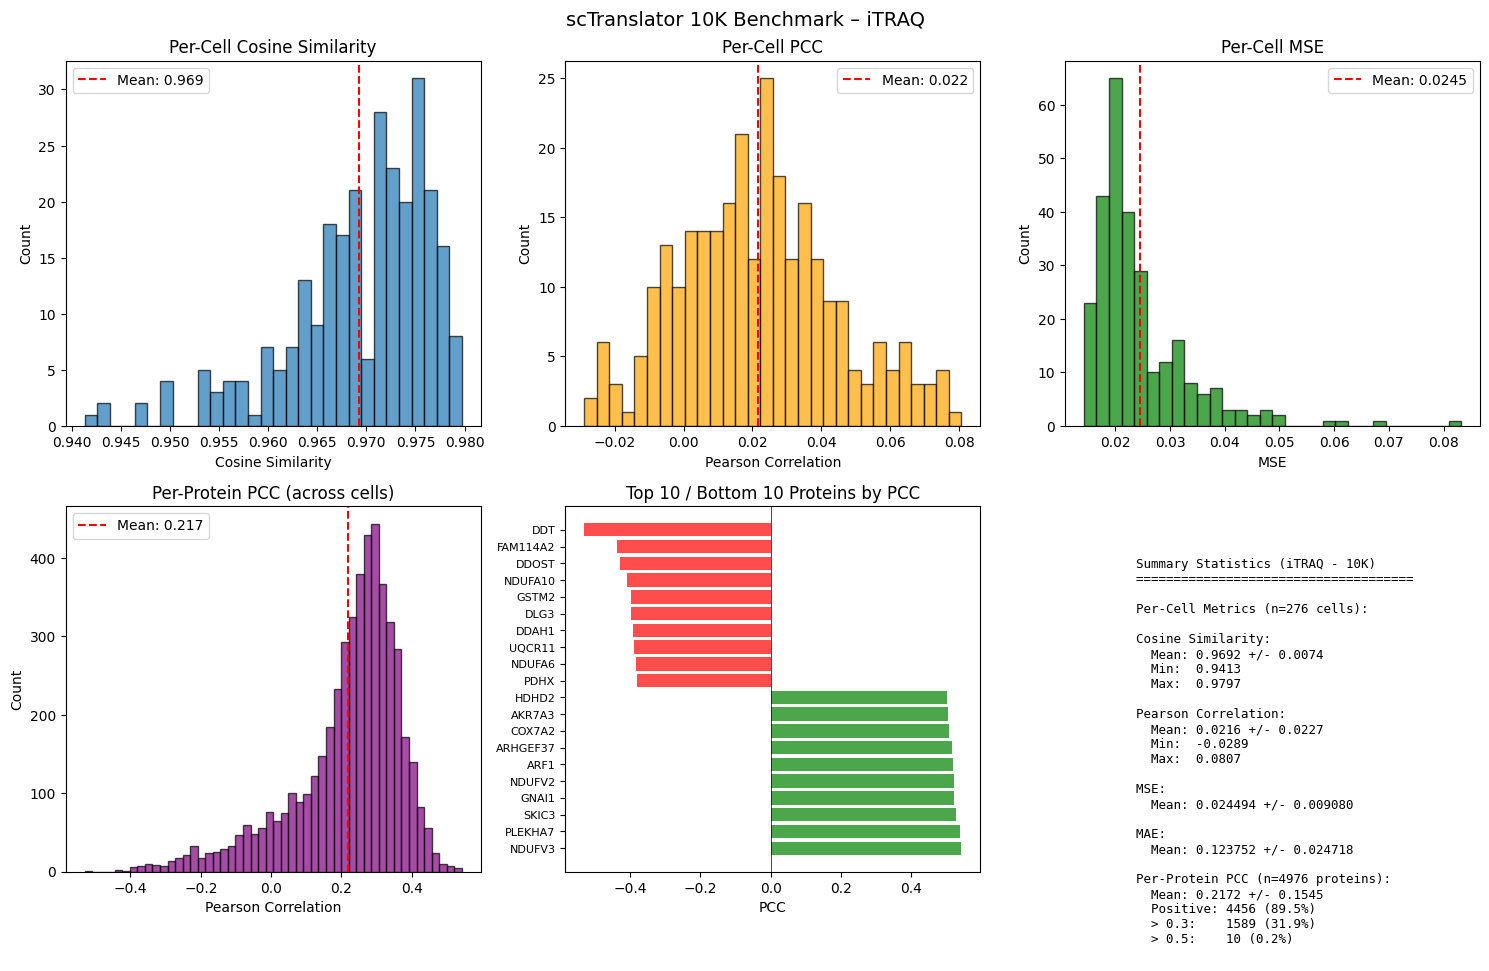

  Saved plot: benchmark_iTRAQ_10K.png


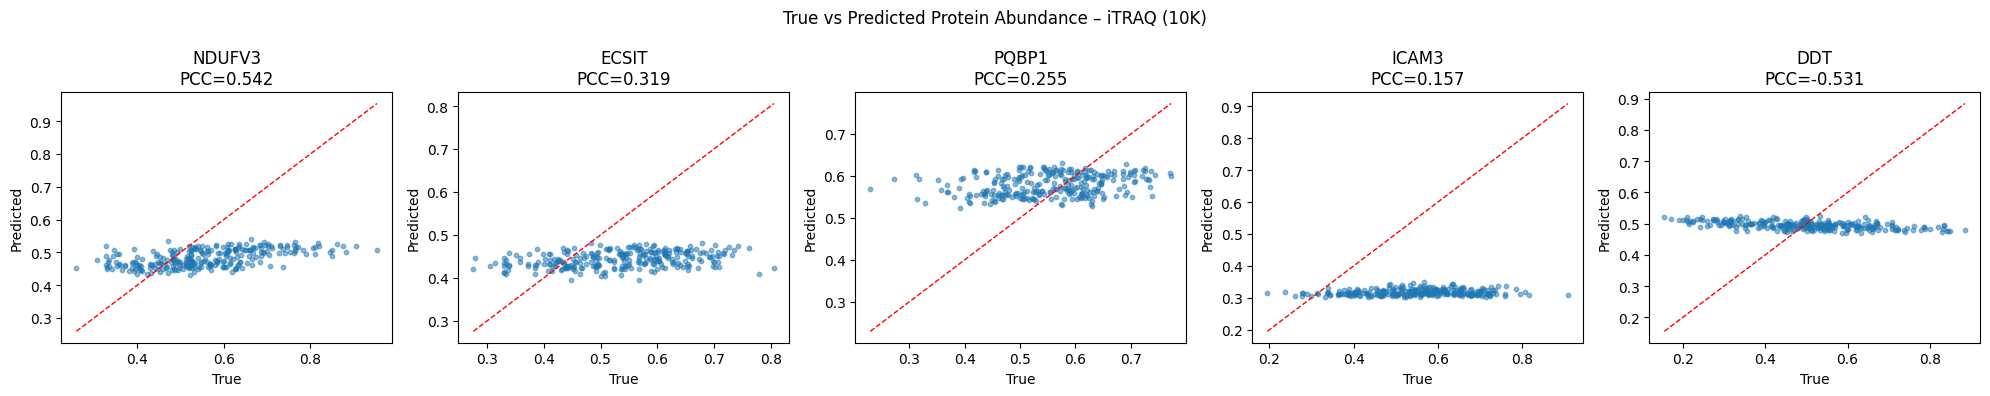

  Saved plot: scatter_iTRAQ_10K.png

############################################################
  DATASET: LabelFree
############################################################

--- Preparing data ---
Loading data...
RNA shape (raw):     (360, 14947)
Protein shape (raw): (360, 2563)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 14947 (0.0%)
  RNA genes filled   (<=50% NaN):  4,020 / 14947 (26.9%)
  Proteins dropped   (>50% NaN): 0 / 2563 (0.0%)
  Proteins filled    (<=50% NaN):  1,410 / 2563 (55.0%)
  RNA shape after:     (360, 14947)
  Protein shape after: (360, 2563)

Mapping RNA genes to scTranslator IDs...
  RNA genes after NaN removal: 14947
  Mapped to scTranslator:      14149 (94.7%)
  Unmapped (thrown out):        798 (5.3%)
  First 20 unmapped genes:     ['ABC12-49244600F4.3', 'ABC7-42389800N19.1', 'AC002055.4', 'AC002310.1', 'AC002467.7', 'AC002472.8', 'AC002472.9', 'AC003665.1', 'AC003682.1', 'AC004080.12', 'AC00438

  Chunk 1: 100%|██████████| 45/45 [00:13<00:00,  3.30it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 45/45 [00:13<00:00,  3.37it/s]


  Chunk 3/3: proteins 2000-2557 (557 proteins)


  Chunk 3: 100%|██████████| 45/45 [00:12<00:00,  3.50it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval\LabelFree\predictions_10K.npy

Computing metrics...

--- Results for LabelFree (10K) ---
Per-Cell Cosine: 0.8833 +/- 0.0615
Per-Cell PCC:    0.0244 +/- 0.0261
Per-Cell MSE:    0.093966 +/- 0.025828
Per-Cell MAE:    0.254084 +/- 0.037410
Per-Protein PCC: 0.0714 +/- 0.3057
Per-Protein Cos: 0.8774 +/- 0.0958

Generating visualizations...


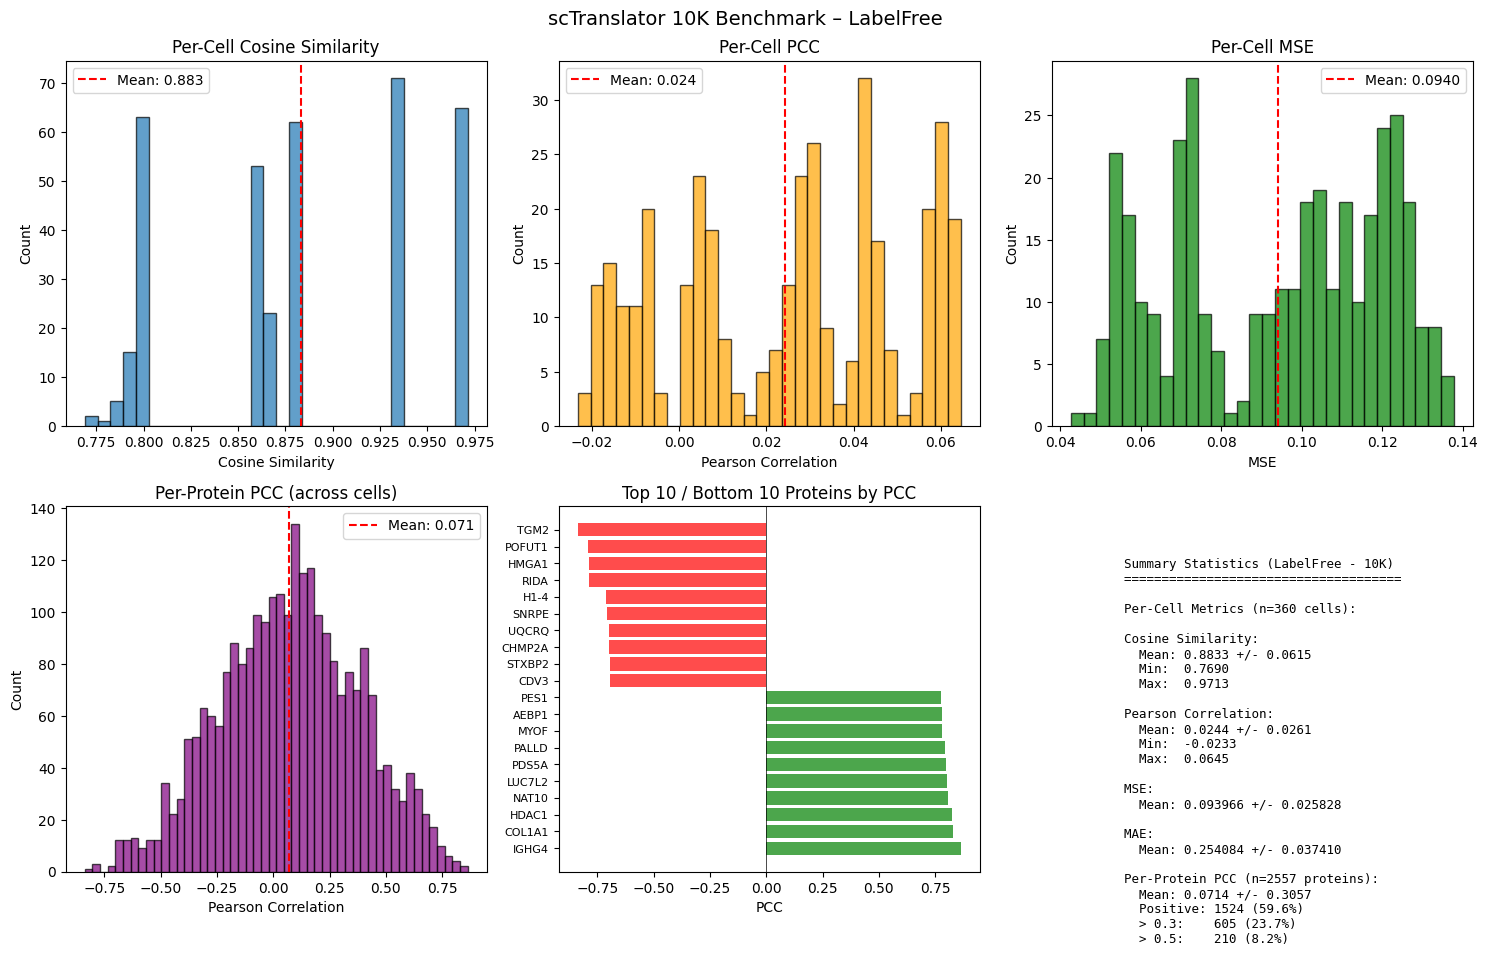

  Saved plot: benchmark_LabelFree_10K.png


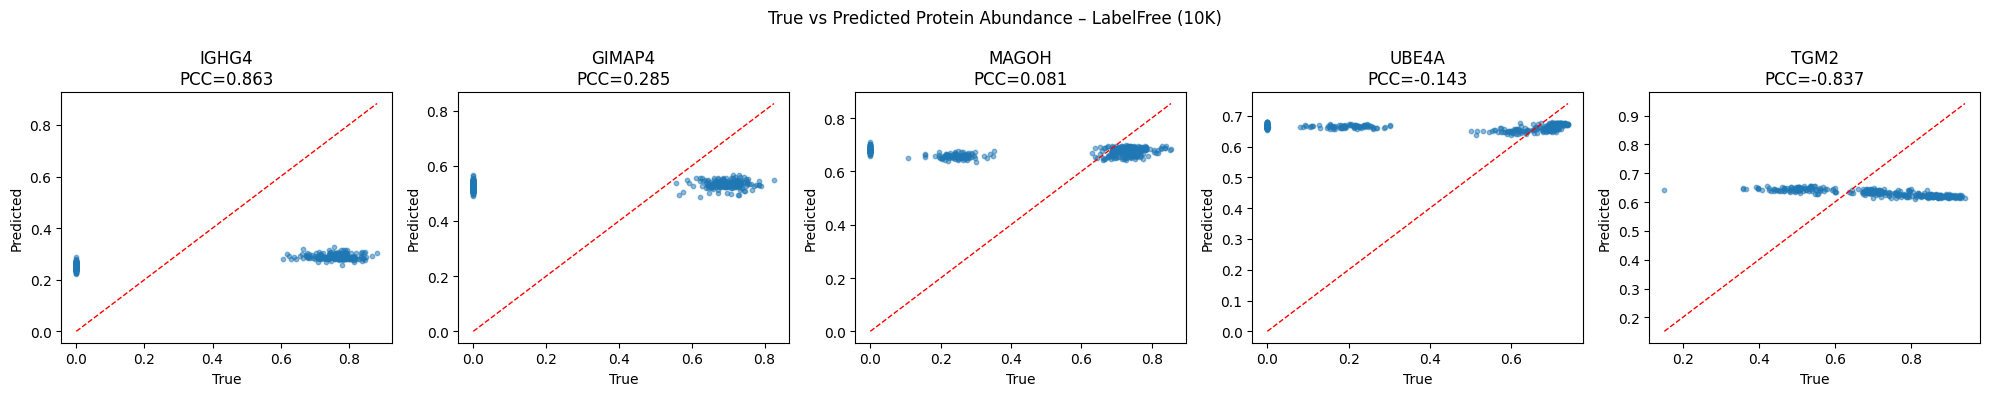

  Saved plot: scatter_LabelFree_10K.png

############################################################
  DATASET: TMT
############################################################

--- Preparing data ---
Loading data...
RNA shape (raw):     (1924, 15001)
Protein shape (raw): (1924, 6885)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 15001 (0.0%)
  RNA genes filled   (<=50% NaN):  7,844 / 15001 (52.3%)
  Proteins dropped   (>50% NaN): 0 / 6885 (0.0%)
  Proteins filled    (<=50% NaN):  5,000 / 6885 (72.6%)
  RNA shape after:     (1924, 15001)
  Protein shape after: (1924, 6885)

Mapping RNA genes to scTranslator IDs...
  RNA genes after NaN removal: 15001
  Mapped to scTranslator:      14522 (96.8%)
  Unmapped (thrown out):        479 (3.2%)
  First 20 unmapped genes:     ['ABC12-49244600F4.3', 'ABC7-42389800N19.1', 'AC002055.4', 'AC002472.9', 'AC003682.1', 'AC004381.6', 'AC004410.1', 'AC004696.1', 'AC004706.1', 'AC004985.13', 'AC005

  Chunk 1: 100%|██████████| 241/241 [01:04<00:00,  3.72it/s]


  Chunk 2/7: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 241/241 [01:05<00:00,  3.68it/s]


  Chunk 3/7: proteins 2000-3000 (1000 proteins)


  Chunk 3: 100%|██████████| 241/241 [01:08<00:00,  3.51it/s]


... (5 outputs left out)

  Chunk 6: 100%|██████████| 241/241 [01:04<00:00,  3.74it/s]


  Chunk 7/7: proteins 6000-6853 (853 proteins)


  Chunk 7: 100%|██████████| 241/241 [01:08<00:00,  3.49it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval\TMT\predictions_10K.npy

Computing metrics...

--- Results for TMT (10K) ---
Per-Cell Cosine: 0.9635 +/- 0.0198
Per-Cell PCC:    0.0649 +/- 0.1050
Per-Cell MSE:    0.040985 +/- 0.029458
Per-Cell MAE:    0.161153 +/- 0.067997
Per-Protein PCC: -0.2595 +/- 0.2683
Per-Protein Cos: 0.9587 +/- 0.0359

Generating visualizations...


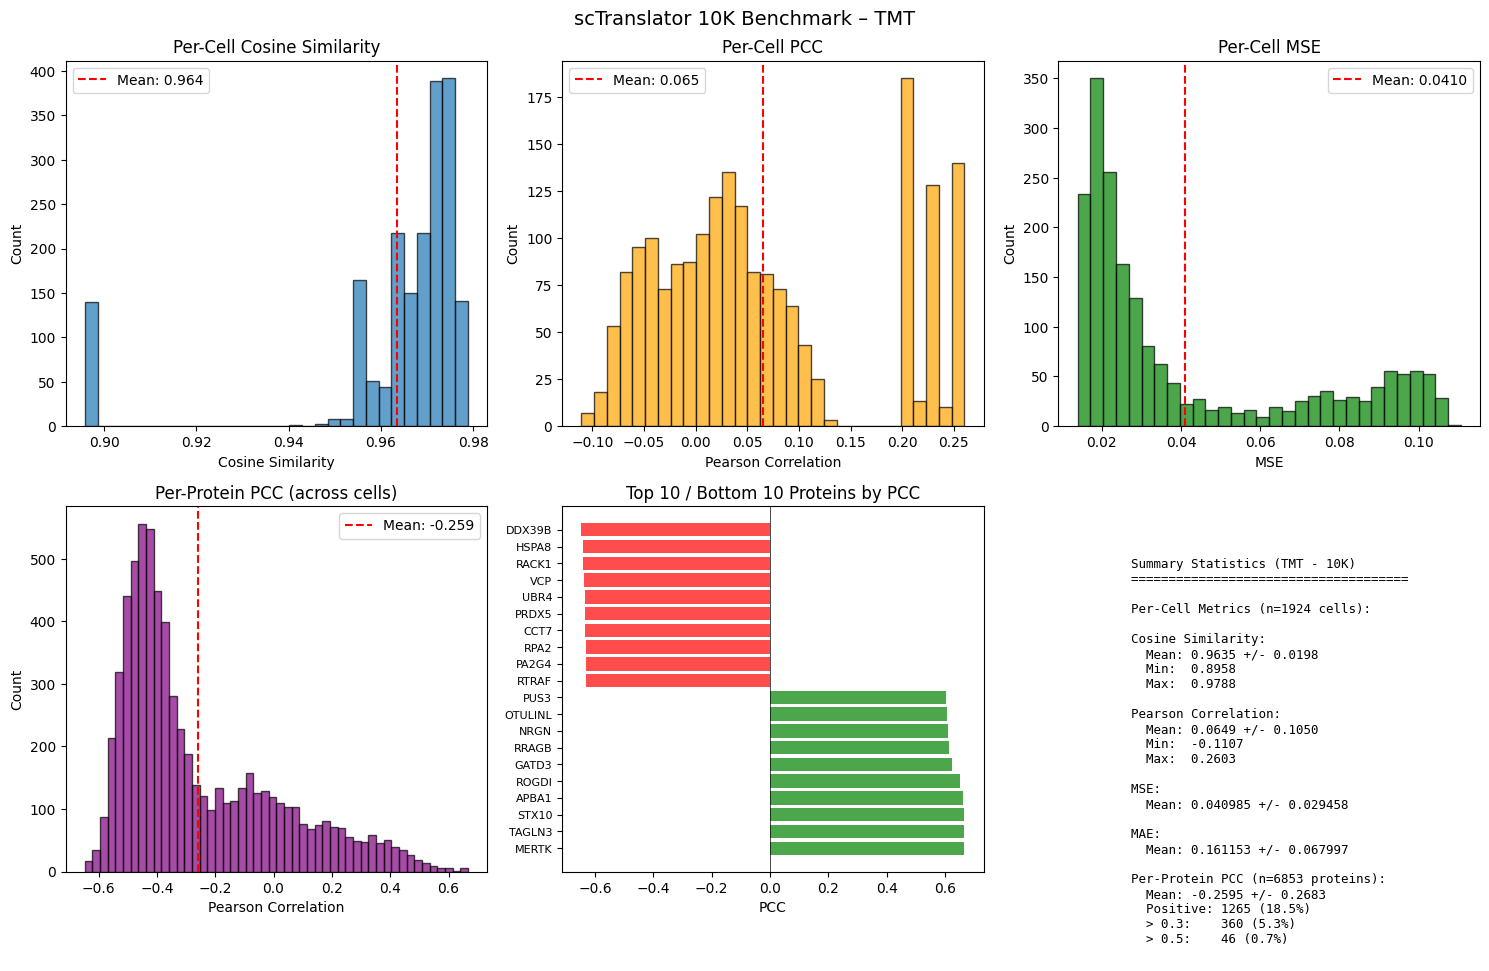

  Saved plot: benchmark_TMT_10K.png


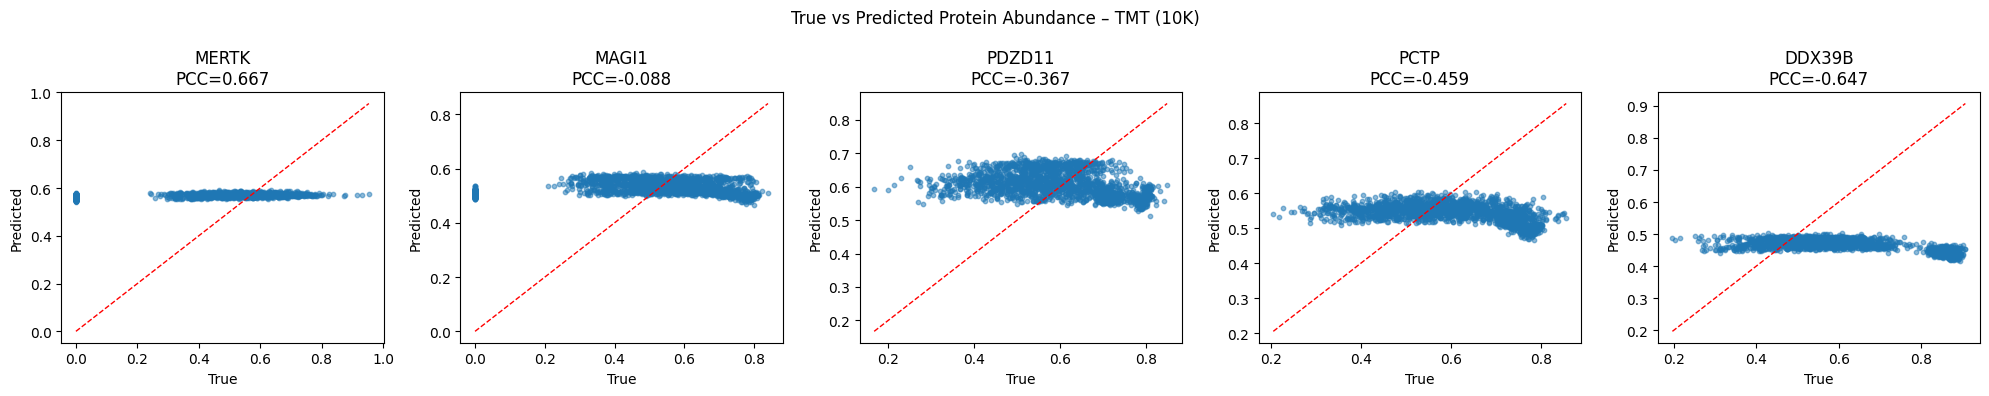

  Saved plot: scatter_TMT_10K.png

All datasets benchmarked successfully!


In [11]:
all_results = {}

for ds_name, ds_paths in DATASETS.items():
    print(f"\n{'#'*60}")
    print(f"  DATASET: {ds_name}")
    print(f"{'#'*60}")

    ds_config = {**COMMON_CONFIG, **ds_paths}

    print("\n--- Preparing data ---")
    ds_data = prepare_data(ds_config)

    results = benchmark_dataset(ds_name, model_10k, ds_data, ds_config, device)
    all_results[ds_name] = results

    if device == 'cuda':
        torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("All datasets benchmarked successfully!")
print("=" * 60)

### 10.3 Dataset Comparison Plot


Generating comparison plots across datasets...


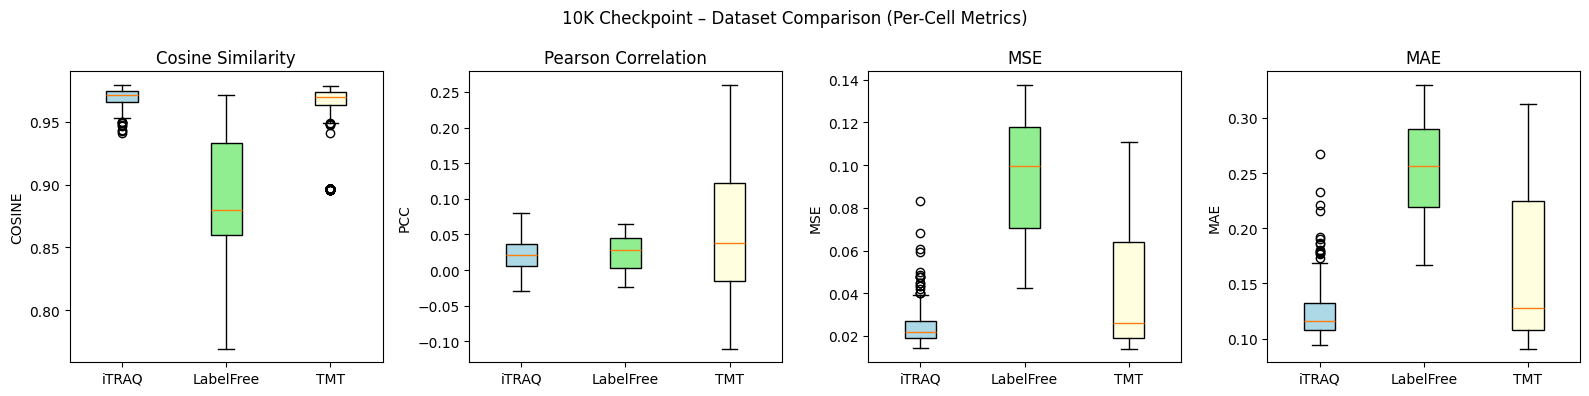

  Saved: dataset_comparison.png


In [12]:
datasets = list(all_results.keys())

if len(all_results) > 1:
    print("\n" + "=" * 60)
    print("Generating comparison plots across datasets...")
    print("=" * 60)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    metrics_to_plot = ['cosine', 'pcc', 'mse', 'mae']
    titles = ['Cosine Similarity', 'Pearson Correlation', 'MSE', 'MAE']

    for ax, metric, title in zip(axes, metrics_to_plot, titles):
        data_to_plot = [all_results[k]['metrics'][metric] for k in datasets]
        labels = datasets

        bp = ax.boxplot(data_to_plot, labels=labels, patch_artist=True)
        colors_bp = ['lightblue', 'lightgreen', 'lightyellow'][:len(labels)]
        for patch, color in zip(bp['boxes'], colors_bp):
            patch.set_facecolor(color)

        ax.set_title(title)
        ax.set_ylabel(metric.upper())

    plt.suptitle('10K Checkpoint \u2013 Dataset Comparison (Per-Cell Metrics)', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(COMMON_CONFIG['output_dir'], 'dataset_comparison.png'), dpi=150)
    plt.show()
    print(f"  Saved: dataset_comparison.png")
else:
    print("Only one (or zero) datasets ran \u2013 skipping comparison plot.")

### 10.4 High Performance Proteins Analysis (Threshold > 0.5)

In [13]:
print("\n" + "="*50)
print("  HIGH PERFORMANCE PROTEINS (> 0.5)")
print("="*50)

for ds in datasets:
    if ds not in all_results:
        continue
    print(f"\nDataset: {ds}")
    res = all_results[ds]

    pcc = res['protein_metrics']['PCC']
    cosine = res['protein_metrics']['Cosine']
    n_total = len(pcc)

    valid_mask = ~np.isnan(pcc)
    pcc_valid = pcc[valid_mask]
    n_total_valid_pcc = len(pcc_valid)

    valid_mask_cos = ~np.isnan(cosine)
    cos_valid = cosine[valid_mask_cos]
    n_total_valid_cos = len(cos_valid)

    n_pcc_05 = np.sum(pcc_valid > 0.5)
    prop_pcc = n_pcc_05 / n_total_valid_pcc if n_total_valid_pcc > 0 else 0

    n_cos_05 = np.sum(cos_valid > 0.5)
    prop_cos = n_cos_05 / n_total_valid_cos if n_total_valid_cos > 0 else 0

    print(f"  Total Proteins (PCC valid): {n_total_valid_pcc}")
    print(f"  Pearson > 0.5: {n_pcc_05} ({prop_pcc:.2%})")
    print(f"  Cosine  > 0.5: {n_cos_05} ({prop_cos:.2%})")


  HIGH PERFORMANCE PROTEINS (> 0.5)

Dataset: iTRAQ
  Total Proteins (PCC valid): 4976
  Pearson > 0.5: 10 (0.20%)
  Cosine  > 0.5: 4974 (99.96%)

Dataset: LabelFree
  Total Proteins (PCC valid): 2557
  Pearson > 0.5: 210 (8.21%)
  Cosine  > 0.5: 2557 (100.00%)

Dataset: TMT
  Total Proteins (PCC valid): 6853
  Pearson > 0.5: 46 (0.67%)
  Cosine  > 0.5: 6850 (99.96%)


### 10.5 Final Summary & Save

In [14]:
print("\n" + "=" * 60)
print("FINAL SUMMARY (10K Checkpoint)")
print("=" * 60)

summary_lines = []
for ds_name, results in all_results.items():
    m  = results['metrics']
    pm = results['protein_metrics']
    line = (f"{ds_name}: Cosine={m['cosine'].mean():.4f}, "
            f"PCC={m['pcc'].mean():.4f}, MSE={m['mse'].mean():.6f}, "
            f"Protein-PCC={pm['PCC'].mean():.4f}, "
            f"Protein-Cos={pm['Cosine'].mean():.4f}")
    print(line)
    summary_lines.append(line)

with open(os.path.join(COMMON_CONFIG['output_dir'], 'summary.txt'), 'w') as f:
    f.write("scTranslator 10K Benchmark Summary \u2013 3 Validation Datasets\n")
    f.write("=" * 60 + "\n\n")

    for ds_name, results in all_results.items():
        ms = results['mapping_stats']
        f.write(f"Dataset: {ds_name}\n")
        f.write("-" * 50 + "\n")
        f.write(f"  Raw dataset: {results['n_cells']} samples x "
                f"{ms['prot_total']} proteins, {ms['rna_total']} RNA genes\n")
        f.write(f"  Final input: {results['n_cells']} samples x "
                f"{results['n_proteins']} proteins, {results['n_rna_genes']} RNA genes\n")
        f.write(f"  RNA attrition:  {ms['rna_total']} -> {ms['rna_mapped']}\n")
        f.write(f"  Prot attrition: {ms['prot_total']} -> {ms['prot_mapped']}\n\n")

    f.write("\nBenchmark Results (10K Checkpoint)\n")
    f.write("-" * 50 + "\n")
    for line in summary_lines:
        f.write(line + "\n")

    f.write("\n\nHigh Performance Proteins (> 0.5)\n")
    f.write("-" * 50 + "\n")
    for ds_name in datasets:
        if ds_name not in all_results:
            continue
        res = all_results[ds_name]
        pcc = res['protein_metrics']['PCC']
        cosine = res['protein_metrics']['Cosine']

        valid_pcc = pcc[~np.isnan(pcc)]
        valid_cos = cosine[~np.isnan(cosine)]

        n_pcc_05 = np.sum(valid_pcc > 0.5)
        n_cos_05 = np.sum(valid_cos > 0.5)
        prop_pcc = n_pcc_05 / len(valid_pcc) if len(valid_pcc) > 0 else 0
        prop_cos = n_cos_05 / len(valid_cos) if len(valid_cos) > 0 else 0

        f.write(f"  {ds_name}: PCC>0.5 = {n_pcc_05}/{len(valid_pcc)} ({prop_pcc:.2%}), "
                f"Cosine>0.5 = {n_cos_05}/{len(valid_cos)} ({prop_cos:.2%})\n")

print(f"\nResults saved to: {COMMON_CONFIG['output_dir']}")
print("Done!")


FINAL SUMMARY (10K Checkpoint)
iTRAQ: Cosine=0.9692, PCC=0.0216, MSE=0.024494, Protein-PCC=0.2172, Protein-Cos=0.9781
LabelFree: Cosine=0.8833, PCC=0.0244, MSE=0.093966, Protein-PCC=0.0714, Protein-Cos=0.8774
TMT: Cosine=0.9635, PCC=0.0649, MSE=0.040985, Protein-PCC=-0.2595, Protein-Cos=0.9587

Results saved to: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval
Done!


---
## 11. Overlap-Only Benchmark (overlap_ALL_4 genes & proteins)

Re-runs the same 10K benchmark on all three validation datasets, but **restricted to only the genes and proteins present in all 4 datasets** (`overlap_ALL_4_genes.txt` and `overlap_ALL_4_proteins.txt`).


### 11.1 Overlap Configuration

In [18]:
OVERLAP_GENES_PATH    = os.path.join(SCRIPT_DIR, 'overlap_ALL_4_genes.txt')
OVERLAP_PROTEINS_PATH = os.path.join(SCRIPT_DIR, 'overlap_ALL_4_proteins.txt')

OVERLAP_OUTPUT_DIR = os.path.join(SCRIPT_DIR, 'benchmark_results_10K_allval_OVERLAP')

genes_ok = 'FOUND' if os.path.exists(OVERLAP_GENES_PATH) else 'MISSING'
prots_ok = 'FOUND' if os.path.exists(OVERLAP_PROTEINS_PATH) else 'MISSING'
print(f"Overlap genes list:    [{genes_ok}] {OVERLAP_GENES_PATH}")
print(f"Overlap proteins list: [{prots_ok}] {OVERLAP_PROTEINS_PATH}")

if genes_ok == 'FOUND':
    n_overlap_genes = len(pd.read_csv(OVERLAP_GENES_PATH, header=None))
    print(f"  -> {n_overlap_genes} overlap genes")
if prots_ok == 'FOUND':
    n_overlap_prots = len(pd.read_csv(OVERLAP_PROTEINS_PATH, header=None))
    print(f"  -> {n_overlap_prots} overlap proteins")

Overlap genes list:    [FOUND] c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\overlap_ALL_4_genes.txt
Overlap proteins list: [FOUND] c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\overlap_ALL_4_proteins.txt
  -> 11935 overlap genes
  -> 2157 overlap proteins


### 11.2 Run 10K Overlap Benchmark on All Validation Datasets

scTranslator 10K OVERLAP Benchmark – 3 Validation Datasets

############################################################
  DATASET (OVERLAP): iTRAQ
############################################################

--- Preparing data (overlap-restricted) ---
Loading data...
RNA shape (raw):     (276, 14521)
Protein shape (raw): (276, 4994)
[OVERLAP] Restricted RNA genes to overlap list: 11935 allowed -> 11935 kept
[OVERLAP] Restricted proteins to overlap list:  2157 allowed -> 2157 kept
[OVERLAP] RNA shape (after overlap filter):     (276, 11935)
[OVERLAP] Protein shape (after overlap filter): (276, 2157)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 11935 (0.0%)
  RNA genes filled   (<=50% NaN):  740 / 11935 (6.2%)
  Proteins dropped   (>50% NaN): 0 / 2157 (0.0%)
  Proteins filled    (<=50% NaN):  99 / 2157 (4.6%)
  RNA shape after:     (276, 11935)
  Protein shape after: (276, 2157)

Mapping RNA genes to scTranslator IDs...
  RNA ge

  Chunk 1: 100%|██████████| 35/35 [00:08<00:00,  4.22it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 35/35 [00:08<00:00,  4.21it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 35/35 [00:08<00:00,  4.18it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval_OVERLAP\iTRAQ\predictions_10K.npy

Computing metrics...

--- Results for iTRAQ (10K) ---
Per-Cell Cosine: 0.9715 +/- 0.0099
Per-Cell PCC:    0.0060 +/- 0.0219
Per-Cell MSE:    0.025239 +/- 0.013055
Per-Cell MAE:    0.125622 +/- 0.034724
Per-Protein PCC: 0.2000 +/- 0.1694
Per-Protein Cos: 0.9713 +/- 0.0137

Generating visualizations...


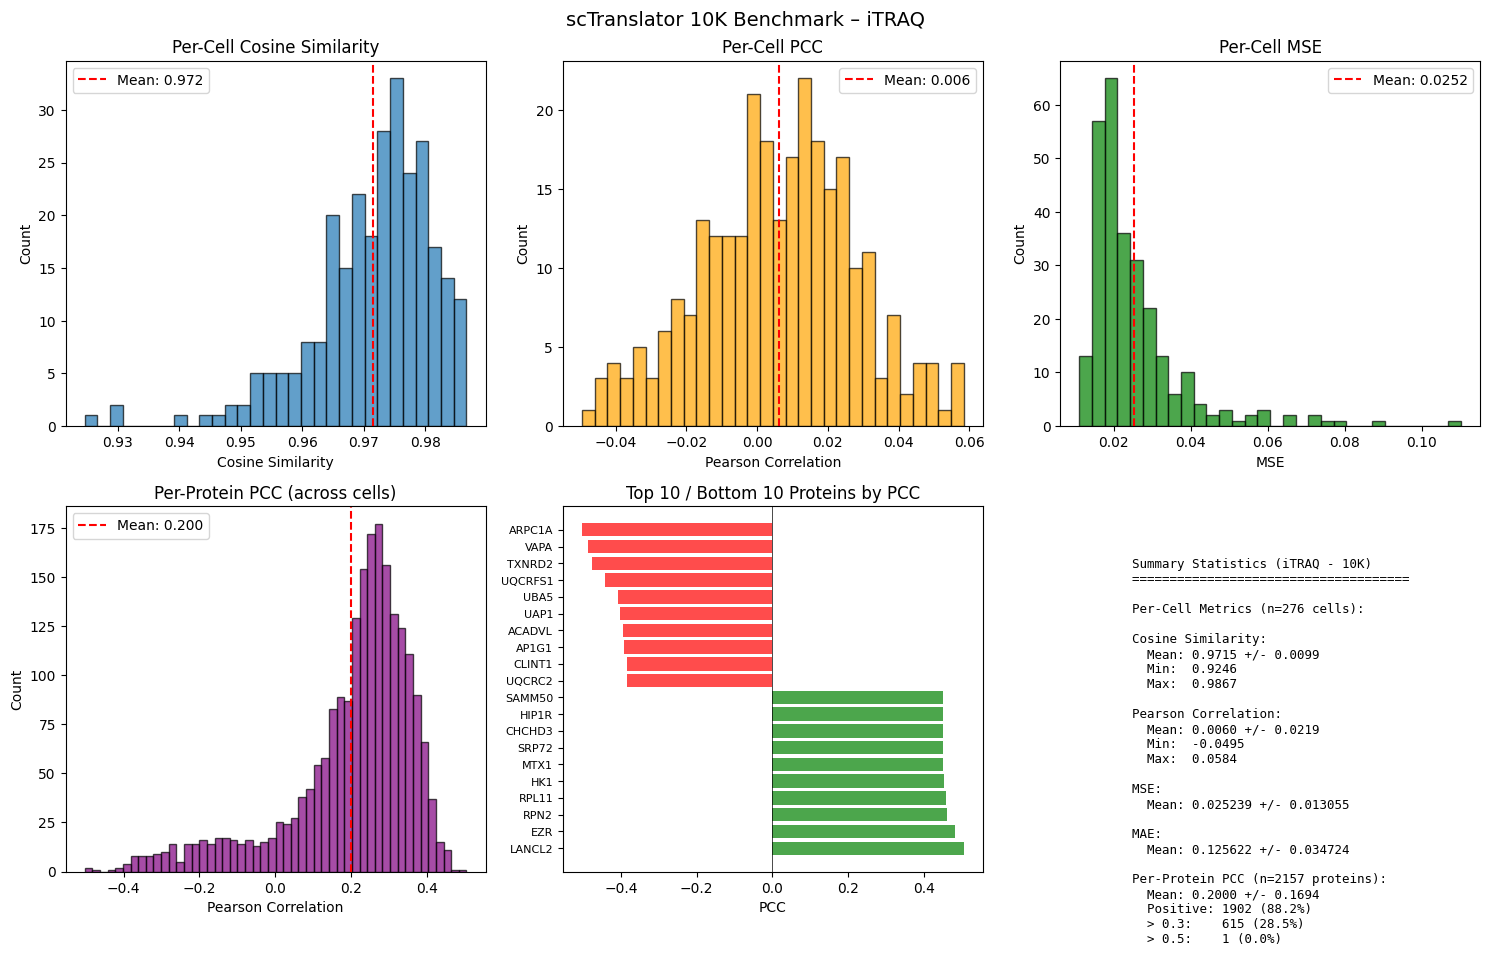

  Saved plot: benchmark_iTRAQ_10K.png


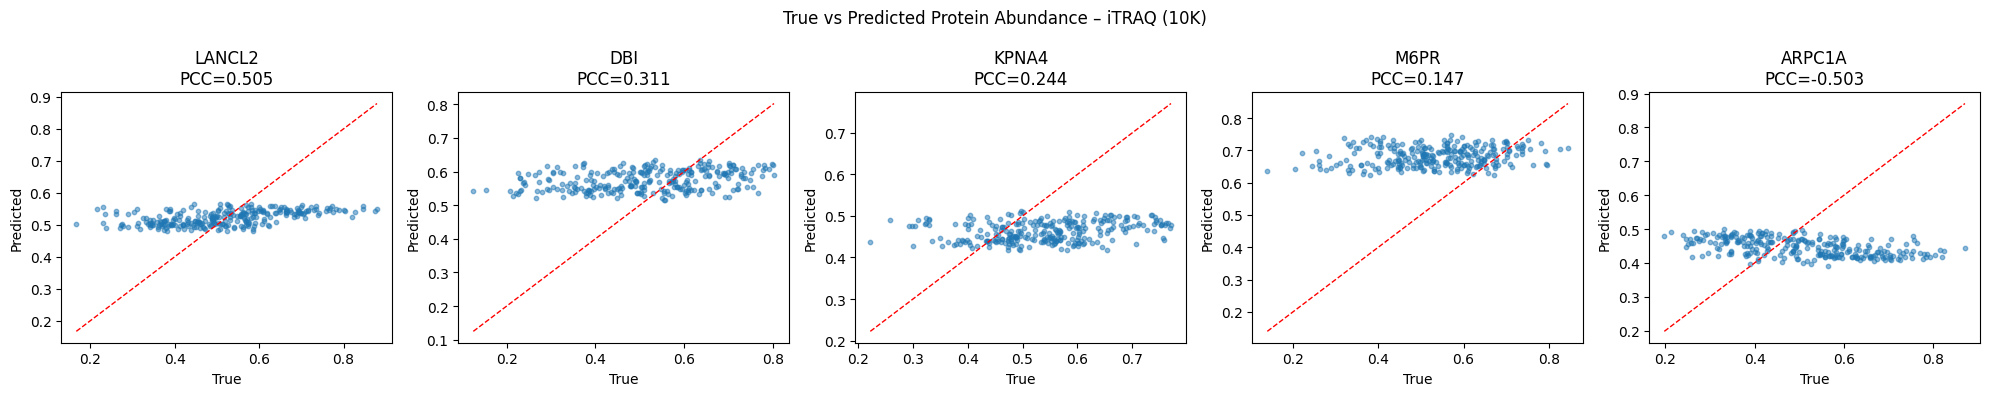

  Saved plot: scatter_iTRAQ_10K.png

############################################################
  DATASET (OVERLAP): LabelFree
############################################################

--- Preparing data (overlap-restricted) ---
Loading data...
RNA shape (raw):     (360, 14947)
Protein shape (raw): (360, 2563)
[OVERLAP] Restricted RNA genes to overlap list: 11935 allowed -> 11935 kept
[OVERLAP] Restricted proteins to overlap list:  2157 allowed -> 2157 kept
[OVERLAP] RNA shape (after overlap filter):     (360, 11935)
[OVERLAP] Protein shape (after overlap filter): (360, 2157)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 11935 (0.0%)
  RNA genes filled   (<=50% NaN):  2,096 / 11935 (17.6%)
  Proteins dropped   (>50% NaN): 0 / 2157 (0.0%)
  Proteins filled    (<=50% NaN):  1,123 / 2157 (52.1%)
  RNA shape after:     (360, 11935)
  Protein shape after: (360, 2157)

Mapping RNA genes to scTranslator IDs...
  RNA genes after Na

  Chunk 1: 100%|██████████| 45/45 [00:10<00:00,  4.16it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 45/45 [00:10<00:00,  4.48it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 45/45 [00:09<00:00,  4.52it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval_OVERLAP\LabelFree\predictions_10K.npy

Computing metrics...

--- Results for LabelFree (10K) ---
Per-Cell Cosine: 0.8908 +/- 0.0584
Per-Cell PCC:    0.0189 +/- 0.0319
Per-Cell MSE:    0.095602 +/- 0.029190
Per-Cell MAE:    0.256807 +/- 0.043758
Per-Protein PCC: 0.0471 +/- 0.2769
Per-Protein Cos: 0.8830 +/- 0.0939

Generating visualizations...


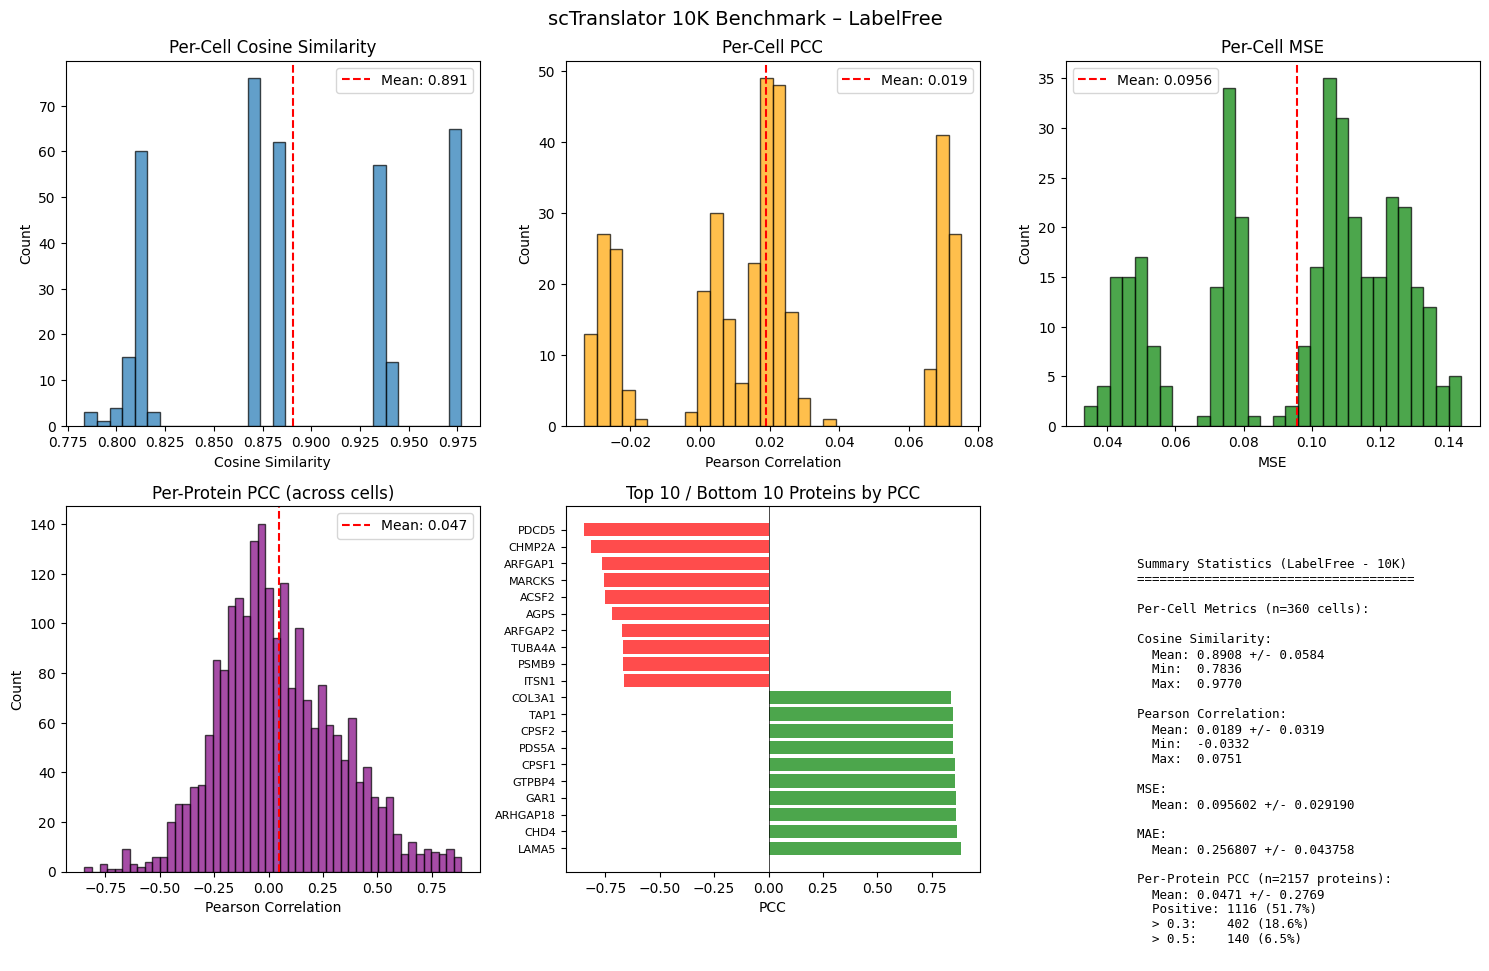

  Saved plot: benchmark_LabelFree_10K.png


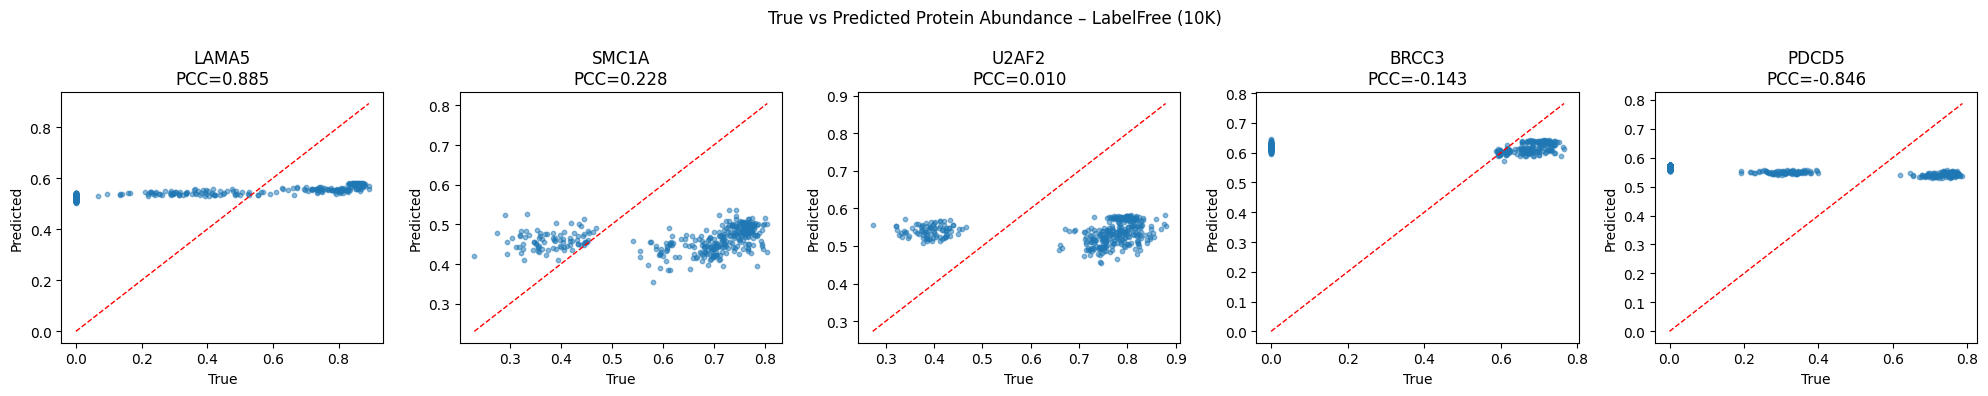

  Saved plot: scatter_LabelFree_10K.png

############################################################
  DATASET (OVERLAP): TMT
############################################################

--- Preparing data (overlap-restricted) ---
Loading data...
RNA shape (raw):     (1924, 15001)
Protein shape (raw): (1924, 6885)
[OVERLAP] Restricted RNA genes to overlap list: 11935 allowed -> 11935 kept
[OVERLAP] Restricted proteins to overlap list:  2157 allowed -> 2157 kept
[OVERLAP] RNA shape (after overlap filter):     (1924, 11935)
[OVERLAP] Protein shape (after overlap filter): (1924, 2157)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 11935 (0.0%)
  RNA genes filled   (<=50% NaN):  5,157 / 11935 (43.2%)
  Proteins dropped   (>50% NaN): 0 / 2157 (0.0%)
  Proteins filled    (<=50% NaN):  1,072 / 2157 (49.7%)
  RNA shape after:     (1924, 11935)
  Protein shape after: (1924, 2157)

Mapping RNA genes to scTranslator IDs...
  RNA genes afte

  Chunk 1: 100%|██████████| 241/241 [01:41<00:00,  2.36it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 241/241 [01:05<00:00,  3.68it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 241/241 [01:01<00:00,  3.91it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\10k benchmark on all val\benchmark_results_10K_allval_OVERLAP\TMT\predictions_10K.npy

Computing metrics...

--- Results for TMT (10K) ---
Per-Cell Cosine: 0.9746 +/- 0.0095
Per-Cell PCC:    0.0145 +/- 0.0273
Per-Cell MSE:    0.043681 +/- 0.030243
Per-Cell MAE:    0.171700 +/- 0.072584
Per-Protein PCC: -0.3662 +/- 0.2089
Per-Protein Cos: 0.9527 +/- 0.0128

Generating visualizations...


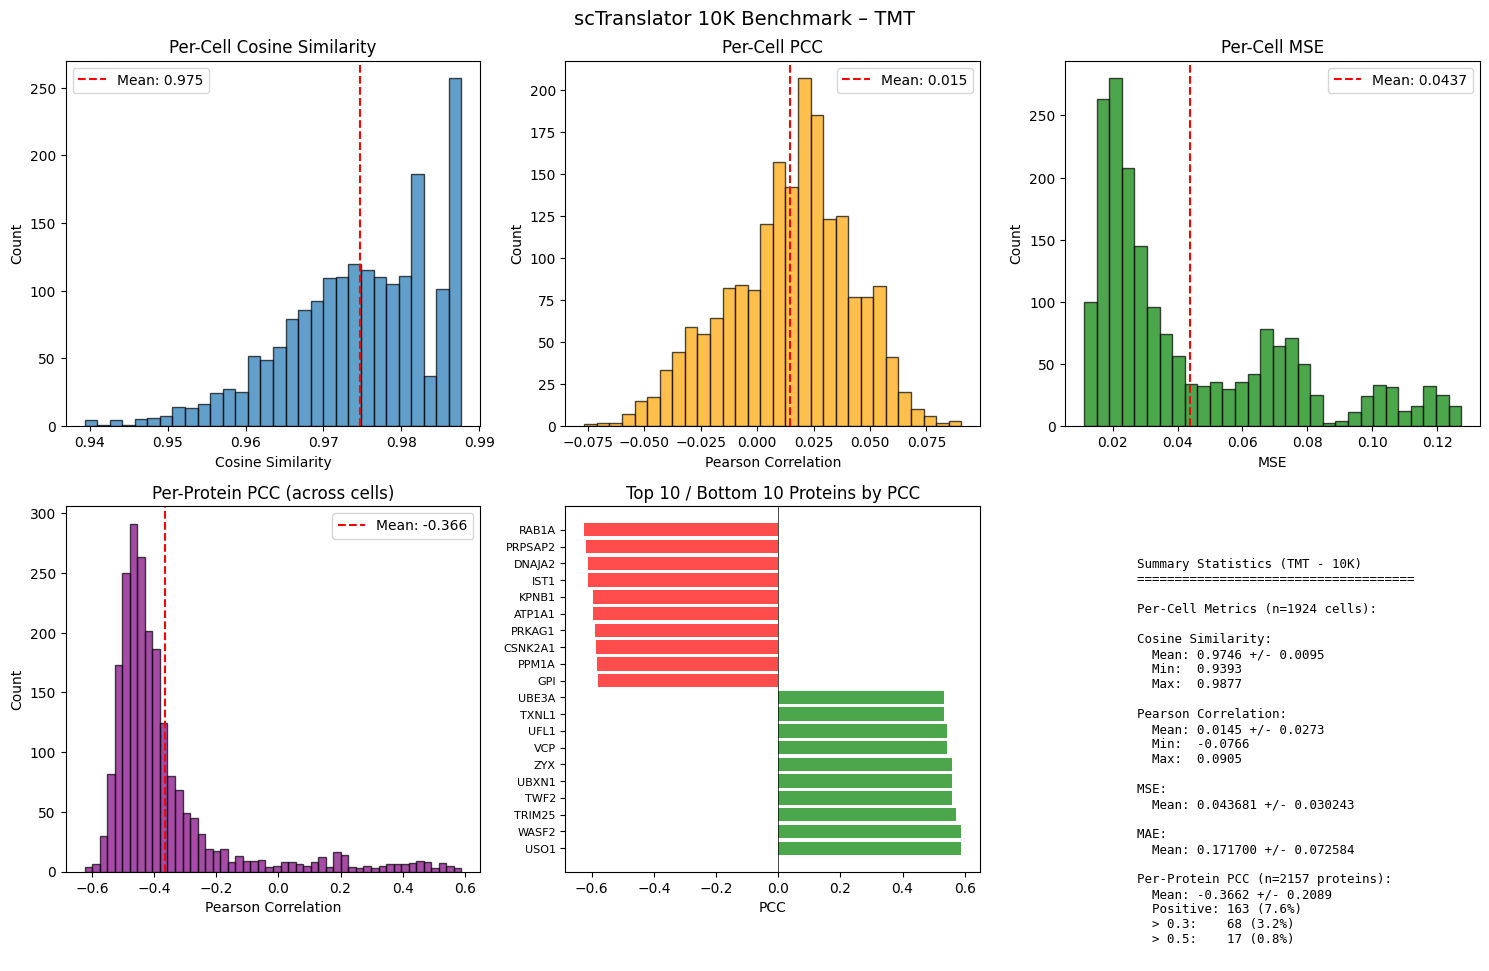

  Saved plot: benchmark_TMT_10K.png


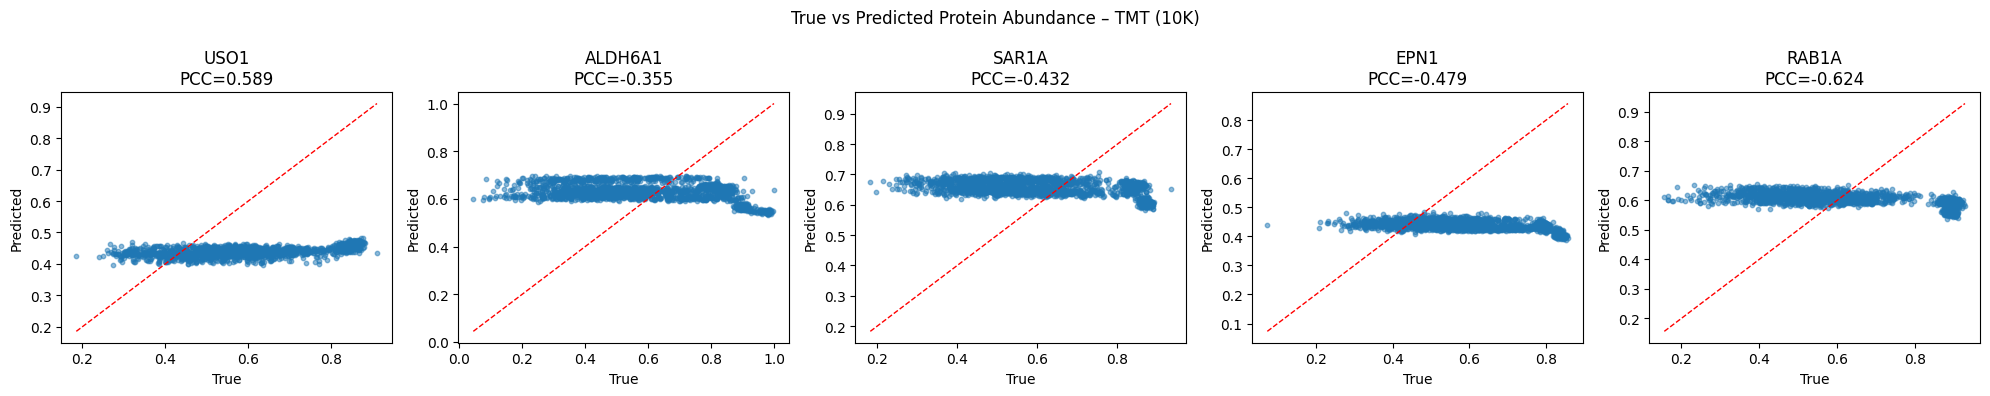

  Saved plot: scatter_TMT_10K.png

All datasets (OVERLAP) benchmarked successfully!


In [19]:
print("=" * 60)
print("scTranslator 10K OVERLAP Benchmark \u2013 3 Validation Datasets")
print("=" * 60)

all_results_overlap = {}

for ds_name, ds_paths in DATASETS.items():
    print(f"\n{'#'*60}")
    print(f"  DATASET (OVERLAP): {ds_name}")
    print(f"{'#'*60}")

    ds_config = {
        **COMMON_CONFIG,
        **ds_paths,
        'overlap_genes_path':    OVERLAP_GENES_PATH,
        'overlap_proteins_path': OVERLAP_PROTEINS_PATH,
        'output_dir':            OVERLAP_OUTPUT_DIR,
    }

    print("\n--- Preparing data (overlap-restricted) ---")
    ds_data = prepare_data(ds_config)

    results = benchmark_dataset(ds_name, model_10k, ds_data, ds_config, device)
    all_results_overlap[ds_name] = results

    if device == 'cuda':
        torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("All datasets (OVERLAP) benchmarked successfully!")
print("=" * 60)

### 11.3 Overlap Dataset Comparison Plot


Generating OVERLAP comparison plots across datasets...


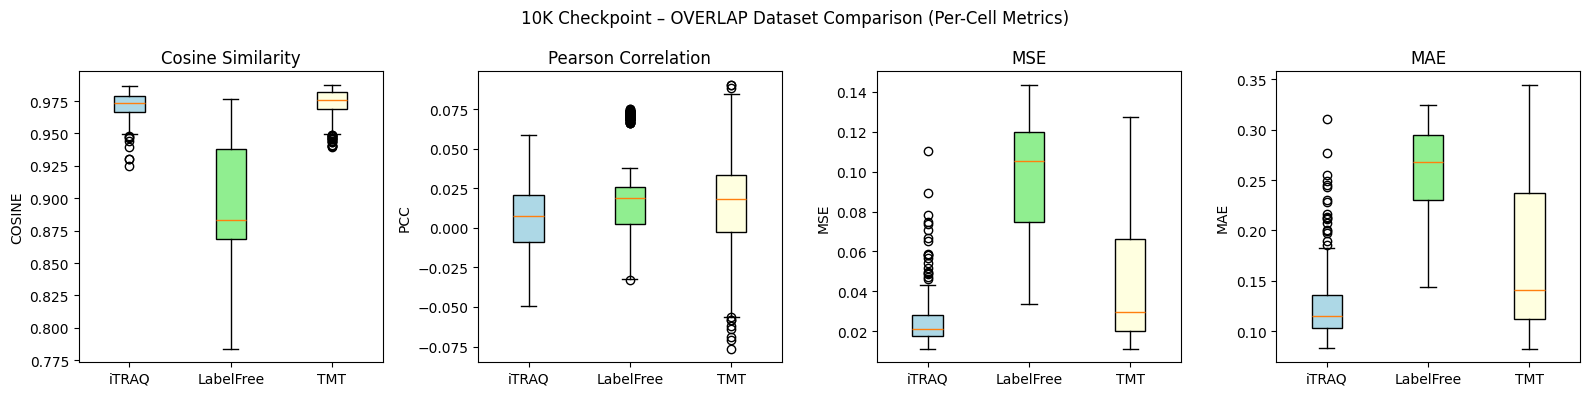

  Saved: dataset_comparison_overlap.png


In [20]:
datasets_overlap = list(all_results_overlap.keys())

if len(all_results_overlap) > 1:
    print("\n" + "=" * 60)
    print("Generating OVERLAP comparison plots across datasets...")
    print("=" * 60)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    metrics_to_plot = ['cosine', 'pcc', 'mse', 'mae']
    titles = ['Cosine Similarity', 'Pearson Correlation', 'MSE', 'MAE']

    for ax, metric, title in zip(axes, metrics_to_plot, titles):
        data_to_plot = [all_results_overlap[k]['metrics'][metric] for k in datasets_overlap]
        labels = datasets_overlap

        bp = ax.boxplot(data_to_plot, labels=labels, patch_artist=True)
        colors_bp = ['lightblue', 'lightgreen', 'lightyellow'][:len(labels)]
        for patch, color in zip(bp['boxes'], colors_bp):
            patch.set_facecolor(color)

        ax.set_title(title)
        ax.set_ylabel(metric.upper())

    plt.suptitle('10K Checkpoint \u2013 OVERLAP Dataset Comparison (Per-Cell Metrics)', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OVERLAP_OUTPUT_DIR, 'dataset_comparison_overlap.png'), dpi=150)
    plt.show()
    print(f"  Saved: dataset_comparison_overlap.png")
else:
    print("Only one (or zero) datasets ran \u2013 skipping comparison plot.")

### 11.4 Overlap High Performance Proteins Analysis (Threshold > 0.5)

In [21]:
print("\n" + "="*50)
print("  HIGH PERFORMANCE PROTEINS \u2013 OVERLAP (> 0.5)")
print("="*50)

for ds in datasets_overlap:
    if ds not in all_results_overlap:
        continue
    print(f"\nDataset: {ds}")
    res = all_results_overlap[ds]

    pcc = res['protein_metrics']['PCC']
    cosine = res['protein_metrics']['Cosine']
    n_total = len(pcc)

    valid_mask = ~np.isnan(pcc)
    pcc_valid = pcc[valid_mask]
    n_total_valid_pcc = len(pcc_valid)

    valid_mask_cos = ~np.isnan(cosine)
    cos_valid = cosine[valid_mask_cos]
    n_total_valid_cos = len(cos_valid)

    n_pcc_05 = np.sum(pcc_valid > 0.5)
    prop_pcc = n_pcc_05 / n_total_valid_pcc if n_total_valid_pcc > 0 else 0

    n_cos_05 = np.sum(cos_valid > 0.5)
    prop_cos = n_cos_05 / n_total_valid_cos if n_total_valid_cos > 0 else 0

    print(f"  Total Proteins (PCC valid): {n_total_valid_pcc}")
    print(f"  Pearson > 0.5: {n_pcc_05} ({prop_pcc:.2%})")
    print(f"  Cosine  > 0.5: {n_cos_05} ({prop_cos:.2%})")


  HIGH PERFORMANCE PROTEINS – OVERLAP (> 0.5)

Dataset: iTRAQ
  Total Proteins (PCC valid): 2157
  Pearson > 0.5: 1 (0.05%)
  Cosine  > 0.5: 2157 (100.00%)

Dataset: LabelFree
  Total Proteins (PCC valid): 2157
  Pearson > 0.5: 140 (6.49%)
  Cosine  > 0.5: 2157 (100.00%)

Dataset: TMT
  Total Proteins (PCC valid): 2157
  Pearson > 0.5: 17 (0.79%)
  Cosine  > 0.5: 2157 (100.00%)
